# Scratch GCN

In [3]:
import os
os.chdir(os.path.dirname(os.getcwd())) if os.getcwd().endswith("notebooks") else None
print(os.getcwd())

/mnt/d_drive/AI Projects/graphprobe


In [4]:
import torch
from scratch_gcn.core import *
set_seed(0)
x,y,ei,m=make_dataset(seed=0)
model=GCN(3,16,2); train_model(model,x,y,prep_graph(ei,200),m)
print('manual layer check', check_manual(model,x,ei,node=0))
print('permutation check', check_permutation(model,x,ei))

manual layer check (True, 1.1920928955078125e-07)
permutation check (True, 9.5367431640625e-07)


,model,setting,mean,std
0,MLP,features only,0.840,0.0224
1,GCN,true graph,0.975,0.0000
2,GCN,test-time edges removed 25%,0.975,0.0000
3,GCN,test-time edges removed 50%,0.975,0.0177
4,GCN,test-time edges removed 75%,0.915,0.0379
5,GCN,test-time edges removed 100%,0.825,0.0000
6,GCN,retrained on random graph,0.720,0.1081


,p_out,homophily,gcn,mlp,gap_gcn_minus_mlp
0,0.01,0.8871,1.0000,0.8167,0.1833
1,0.02,0.8020,0.9833,0.8167,0.1666
2,0.04,0.6635,0.8667,0.8167,0.0500
3,0.06,0.5665,0.6500,0.8167,-0.1667
4,0.08,0.4953,0.6167,0.8167,-0.2000


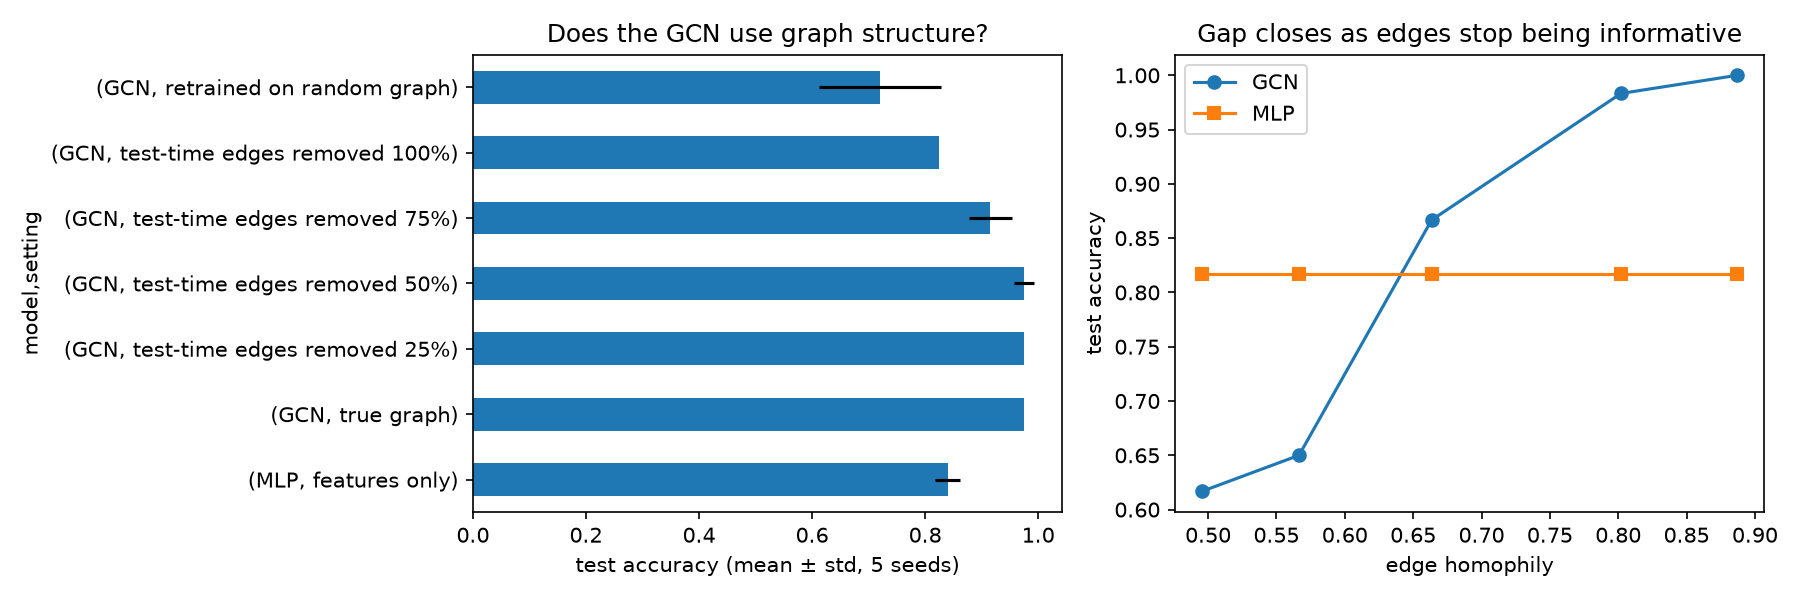

In [5]:
import pandas as pd, json, glob
from IPython.display import Image, display
R='results/scratch_gcn/'
display(pd.read_csv(R+'ablation_results.csv'));display(pd.read_csv(R+'homophily_sweep.csv'));display(Image(R+'structure_evidence.png'))

Dataset design and interpretation: see `report/TECHNICAL_REPORT.md` section 1.